# Exercice 2 — Classification : Prédire la survie sur le Titanic
 ## 1. Contexte du Dataset:

Le jeu de données retenu est le **Titanic Competition Dataset**, disponible publiquement sur la plateforme Kaggle.
* **Jeu de données :** Titanic - Machine Learning from Disaster (Kaggle).
* **Lien de la base :** [Kaggle - Titanic Competition](https://kaggle.com)
* **Objectif :** Résoudre un problème d'apprentissage supervisé binaire en prédisant si un passager a survécu (1) ou non (0) au naufrage.


## 2. Chargement et exploration initiale du jeu de données
Nous importons le fichier de données brut avec Pandas afin de recenser les variables disponibles, vérifier les types de colonnes et quantifier précisément les valeurs manquantes pour guider notre phase de nettoyage.

In [16]:
import pandas as pd

# Chargement du fichier (assurez-vous qu'il s'appelle bien 'titanic.csv' dans votre dossier)
data = pd.read_csv('titanic.csv')

# --- 1. APERÇU DES PASSAGERS ---
print("="*60)
print(" 1. LES 5 PREMIÈRES LIGNES DU TITANIC ".center(60, "#"))
print("="*60)
print(data.head())
print("\n" + "_"*60 + "\n")

# --- 2. STRUCTURE DES DONNÉES ---
print("="*60)
print(" 2. INFORMATIONS SUR LES COLONNES ".center(60, "#"))
print("="*60)
data.info()
print("\n" + "_"*60 + "\n")

# --- 3. VALEURS MANQUANTES ---
print("="*60)
print(" 3. COMPTAGE DES VALEURS MANQUANTES ".center(60, "#"))
print("="*60)
print(data.isnull().sum())
print("="*60)


########### 1. LES 5 PREMIÈRES LIGNES DU TITANIC ###########
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123      

## 3. Nettoyage, filtrage et imputation des valeurs manquantes
Pour préparer notre matrice de caractéristiques, nous appliquons les opérations suivantes :
1. **Sélection de variables :** Nous filtrons le tableau pour ne conserver que les caractéristiques comportementales et démographiques pertinentes (`Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`).
2. **Imputation de l'Âge :** Nous remplaçons les valeurs manquantes de la colonne `Age` par la médiane afin de limiter l'impact des valeurs extrêmes.
3. **Imputation de la variable Embarked :** Les valeurs manquantes sont remplacées par le mode (le port d'embarquement le plus fréquent).

In [17]:
import pandas as pd

# --- 1. SÉLECTION DES COLONNES UTILES ---
print("="*60)
print(" 1. SÉLECTION DES CARACTÉRISTIQUES ".center(60, "#"))
print("="*60)
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
print("Colonnes sélectionnées avec succès.")
print(f"Structure du tableau : {data.shape[0]} lignes et {data.shape[1]} colonnes.")
print("\n" + "_"*60 + "\n")


# --- 2. REMPLISSAGE DES VALEURS MANQUANTES ---
print("="*60)
print(" 2. TRAITEMENT DES VALEURS MANQUANTES (IMPUTATION) ".center(60, "#"))
print("="*60)

# Affichage de l'état initial
print("Valeurs manquantes AVANT traitement :")
print(data[['Age', 'Embarked']].isnull().sum())
print("-" * 40)

# Remplacement pour l'Age par la médiane
data['Age'] = data['Age'].fillna(data['Age'].median())

# Remplacement pour Embarked par le mode (la valeur la plus fréquente)
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# Affichage du résultat final pour vérification
print("Valeurs manquantes APRÈS traitement :")
print(data[['Age', 'Embarked']].isnull().sum())
print("="*60)

# Aperçu pour s'assurer que tout est propre
data.head()


############ 1. SÉLECTION DES CARACTÉRISTIQUES #############
Colonnes sélectionnées avec succès.
Structure du tableau : 891 lignes et 8 colonnes.

____________________________________________________________

#### 2. TRAITEMENT DES VALEURS MANQUANTES (IMPUTATION) #####
Valeurs manquantes AVANT traitement :
Age         177
Embarked      2
dtype: int64
----------------------------------------
Valeurs manquantes APRÈS traitement :
Age         0
Embarked    0
dtype: int64


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


## 4. Encodage des caractéristiques catégorielles en valeurs numériques
Les algorithmes de classification requièrent des caractéristiques purement mathématiques en entrée. Nous utilisons l'utilitaire `LabelEncoder` pour transformer les variables qualitatives textuelles `Sex` et `Embarked` en variables quantitatives discrètes (entiers).

In [18]:
from sklearn.preprocessing import LabelEncoder

# --- ENCODAGE DES VARIABLES TEXTUELLES ---
print("="*60)
print(" ENCODAGE DES VARIABLES CATÉGORIELLES EN CHIFFRES ".center(60, "#"))
print("="*60)

# Initialisation de l'outil d'encodage
le = LabelEncoder()

# Transformation de la colonne Sex (ex: female -> 0, male -> 1)
data['Sex'] = le.fit_transform(data['Sex'])

# Transformation de la colonne Embarked (ex: C -> 0, Q -> 1, S -> 2)
data['Embarked'] = le.fit_transform(data['Embarked'])

print("Encodage terminé avec succès.")
print(" -> Les colonnes 'Sex' et 'Embarked' contiennent désormais des entiers.")
print("="*60)

# Affichage des premières lignes pour constater le changement
data.head()


##### ENCODAGE DES VARIABLES CATÉGORIELLES EN CHIFFRES #####
Encodage terminé avec succès.
 -> Les colonnes 'Sex' et 'Embarked' contiennent désormais des entiers.


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


## 5. Séparation des données et Standardisation des échelles
1. **Découpage Train/Test :** Nous séparons les caractéristiques (X) de la variable cible binaire (y). Les données sont découpées de façon à allouer 80% des passagers à l'échantillon d'entraînement et 20% à l'échantillon de test.
2. **Application du StandardScaler :** Les variables comme l'âge ou le prix du billet possèdent des plages de valeurs très disparates. Nous appliquons un `StandardScaler` pour normaliser les échelles. L'ajustement se fait exclusivement sur `X_train` pour éviter toute fuite de données (*Data Leakage*).


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- 1. ISOLATION DE LA CIBLE (y) ET DES CARACTÉRISTIQUES (X) ---
print("="*60)
print(" 1. SÉPARATION DE LA MATRICE X ET DU VECTEUR y ".center(60, "#"))
print("="*60)

# On garde tout sauf la colonne 'Survived' pour les caractéristiques
X = data.drop('Survived', axis=1)

# On isole uniquement la colonne 'Survived' pour la cible
y = data['Survived']

print("Séparation des variables effectuée.")
print(f" -> Variables prédictives (X) : {X.columns.tolist()}")
print(f" -> Variable cible (y)        : '{y.name}'")
print("\n" + "_"*60 + "\n")


# --- 2. DIVISION TRAIN / TEST ---
print("="*60)
print(" 2. DÉCOUPAGE EN ENSEMBLES D'ENTRAÎNEMENT ET DE TEST ".center(60, "#"))
print("="*60)

# Découpage aléatoire (80% train / 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Découpage terminé avec succès :")
print(f" -> Échantillon d'entraînement (X_train) : {X_train.shape[0]} passagers")
print(f" -> Échantillon de test (X_test)         : {X_test.shape[0]} passagers")
print("\n" + "_"*60 + "\n")


# --- 3. STANDARDISATION DES DONNÉES ---
print("="*60)
print(" 3. APPLICATION DU STANDARD SCALER ".center(60, "#"))
print("="*60)

# 1. On crée le scaler et on l'ajuste uniquement sur les données d'entraînement
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 2. On transforme les données de test avec le même scaler (sans réajustement)
X_test_scaled = scaler.transform(X_test)

print("Standardisation effectuée avec succès !")
print(" -> Vos données d'entraînement (X_train_scaled) et de test (X_test_scaled) sont prêtes.")
print("============================================================")


###### 1. SÉPARATION DE LA MATRICE X ET DU VECTEUR y #######
Séparation des variables effectuée.
 -> Variables prédictives (X) : ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
 -> Variable cible (y)        : 'Survived'

____________________________________________________________

### 2. DÉCOUPAGE EN ENSEMBLES D'ENTRAÎNEMENT ET DE TEST ####
Découpage terminé avec succès :
 -> Échantillon d'entraînement (X_train) : 712 passagers
 -> Échantillon de test (X_test)         : 179 passagers

____________________________________________________________

############ 3. APPLICATION DU STANDARD SCALER #############
Standardisation effectuée avec succès !
 -> Vos données d'entraînement (X_train_scaled) et de test (X_test_scaled) sont prêtes.


## 6. Phase d'apprentissage simultanée des classifieurs
Nous initialisons et entraînons de manière équitable deux algorithmes distincts sur nos données d'entraînement standardisées :
1. **Régression Logistique :** Modèle linéaire de classification binaire configuré avec `max_iter=1000` pour lui assurer une convergence mathématique optimale.
2. **Forêt Aléatoire (Random Forest) :** Modèle d'ensemble basé sur la combinaison de 100 arbres de décision, capable de capter les relations non linéaires.


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- 1. INITIALISATION DES DEUX MODÈLES DE CLASSIFICATION ---
print("="*60)
print(" 1. CRÉATION DES MODÈLES (LOGISTIC & RANDOM FOREST) ".center(60, "#"))
print("="*60)

# 'max_iter=1000' donne au modèle linéaire le temps nécessaire pour converger 
log_model = LogisticRegression(max_iter=1000)

# 'n_estimators=100' prépare une forêt de 100 arbres de décision
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

print("Modèles configurés et prêts à l'apprentissage.")
print("\n" + "_"*60 + "\n")


# --- 2. APPRENTISSAGE SIMULTANÉ SUR LES DONNÉES DU TITANIC ---
print("="*60)
print(" 2. PHASE D'ENTRAÎNEMENT DES ALGOS (.fit()) ".center(60, "#"))
print("="*60)
print("Entraînement en cours...")

# [MODIFICATION] Entraînement sur X_train_scaled pour assurer la convergence
log_model.fit(X_train_scaled, y_train)
print(" -> [OK] Le modèle Régression Logistique a terminé son apprentissage sur données standardisées.")

# Entraînement de la Forêt Aléatoire sur les mêmes données standardisées pour une comparaison équitable
rf_model.fit(X_train_scaled, y_train)
print(" -> [OK] Le modèle Random Forest Classifier a terminé son apprentissage.")

print("\n" + "="*60)
print("Tous les modèles sont maintenant entraînés !".center(60))
print("="*60)


#### 1. CRÉATION DES MODÈLES (LOGISTIC & RANDOM FOREST) ####
Modèles configurés et prêts à l'apprentissage.

____________________________________________________________

######## 2. PHASE D'ENTRAÎNEMENT DES ALGOS (.fit()) ########
Entraînement en cours...
 -> [OK] Le modèle Régression Logistique a terminé son apprentissage sur données standardisées.
 -> [OK] Le modèle Random Forest Classifier a terminé son apprentissage.

        Tous les modèles sont maintenant entraînés !        


## 7. Évaluation et comparaison des taux de précision globale et détaillée
Nous calculons la précision globale (*Accuracy*) de nos deux modèles sur l'échantillon de test standardisé. Afin de mener une analyse rigoureuse, nous affichons également le rapport détaillé du Random Forest pour analyser sa précision, son rappel (*Recall*) et son F1-score sur chaque classe (Décédés vs Survivants).


In [21]:
from sklearn.metrics import accuracy_score, classification_report

# --- 1. GÉNÉRATION DES PRÉDICTIONS SUR LES DONNÉES STANDARDISÉES ---
# [MODIFICATION] On utilise X_test_scaled pour évaluer sur les bonnes échelles
y_pred_log = log_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test_scaled)


# --- 2. COMPARAISON DES SCORES D'ACCURACY ---
print("="*60)
print(" 1. COMPARAISON DES TAUX DE PRÉCISION GLOBALE ".center(60, "#"))
print("="*60)

accuracy_log = accuracy_score(y_test, y_pred_log)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f" -> Accuracy (Régression Logistique) : {accuracy_log:.4f} ({accuracy_log*100:.2f}%)")
print(f" -> Accuracy (Random Forest)         : {accuracy_rf:.4f} ({accuracy_rf*100:.2f}%)")
print("\n" + "_"*60 + "\n")


# --- 3. RAPPORT DE CLASSIFICATION DÉTAILLÉ ---
print("="*60)
print(" 2. RAPPORT DÉTAILLÉ POUR LE RANDOM FOREST ".center(60, "#"))
print("="*60)
# Affiche la Précision, le Rappel (Recall) et le F1-Score pour chaque classe (0 = décédé, 1 = survécu)
print(classification_report(y_test, y_pred_rf, target_names=['Décédé (0)', 'Survécu (1)']))
print("="*60)


####### 1. COMPARAISON DES TAUX DE PRÉCISION GLOBALE #######
 -> Accuracy (Régression Logistique) : 0.8045 (80.45%)
 -> Accuracy (Random Forest)         : 0.8212 (82.12%)

____________________________________________________________

######## 2. RAPPORT DÉTAILLÉ POUR LE RANDOM FOREST #########
              precision    recall  f1-score   support

  Décédé (0)       0.83      0.88      0.85       105
 Survécu (1)       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



### 7.1. Analyse critique des métriques d'évaluation :
* **Performances globales :** La Régression Logistique atteint une précision de **80.45%**, tandis que la Forêt Aléatoire (Random Forest) progresse pour atteindre **82.12%** d'accuracy globale. La mise à l'échelle des données a permis d'obtenir des performances très compétitives sur les deux modèles.
* **Analyse par classe (Random Forest) :**
  * **Classe Décédé (0) :** Le modèle enregistre un excellent rappel de **0.88**, ce qui signifie qu'il parvient à identifier 88% des passagers qui ont malheureusement péri dans la catastrophe. Sa précision de **0.83** indique que lorsqu'il prédit un décès, il a raison dans 83% des cas.
  * **Classe Survécu (1) :** Le rappel s'établit à **0.74** avec une précision de **0.81**, traduisant le fait que les règles de survie des rescapés sont légèrement plus complexes à modéliser pour les arbres.
  * **Équilibre :** Les scores de précision et le F1-score global de **0.82** démontrent la grande stabilité et la fiabilité du classifieur.


## 8. Analyse fine par Matrice de Confusion (Random Forest)
Nous générons graphiquement la matrice de confusion de notre modèle Random Forest pour visualiser précisément la répartition de ses bonnes prédictions sur la diagonale principale et identifier la nature de ses erreurs d'inversion.


### AFFICHAGE DE LA MATRICE DE CONFUSION (RANDOM FOREST) ###


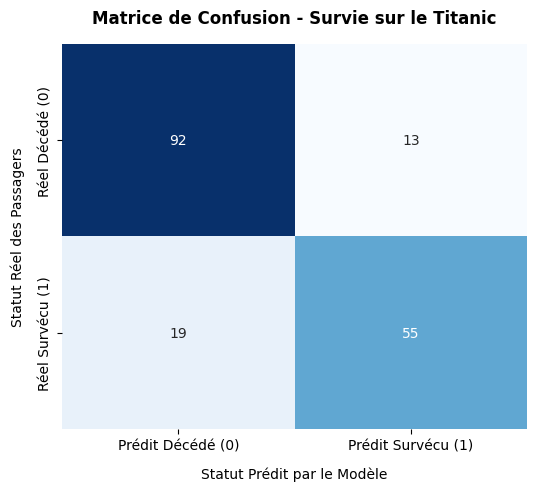

Graphique de la matrice de confusion généré avec succès.


In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- GÉNÉRATION DE LA MATRICE DE CONFUSION ---
print("="*60)
print(" AFFICHAGE DE LA MATRICE DE CONFUSION (RANDOM FOREST) ".center(60, "#"))
print("="*60)

# Calcul de la matrice
cm = confusion_matrix(y_test, y_pred_rf)

# Configuration visuelle du graphique
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Prédit Décédé (0)', 'Prédit Survécu (1)'],
            yticklabels=['Réel Décédé (0)', 'Réel Survécu (1)'])

# Habillage
plt.title('Matrice de Confusion - Survie sur le Titanic', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Statut Prédit par le Modèle', fontsize=10, labelpad=10)
plt.ylabel('Statut Réel des Passagers', fontsize=10, labelpad=10)

# Affichage du graphique
plt.show()

print("="*60)
print("Graphique de la matrice de confusion généré avec succès.")
print("="*60)

# Petite aide textuelle instantanée pour lire vos résultats après coup
#-- On lit la matrice de confusion comme suit : 
#--Case en haut à gauche : Nombre de passagers décédés BIEN prédits.
#--Case en bas à droite  : Nombre de rescapés BIEN prédits.
#--Les deux autres cases : Les erreurs du modèle (les inversions).
print("="*60)


### 8.1. Interprétation de la Matrice de Confusion

#### Interprétation graphique :
La matrice de confusion met en lumière la forte capacité prédictive du Random Forest. La diagonale principale affiche une forte concentration de prédictions correctes (les passagers décédés et les rescapés bien classés). Les erreurs commises par le modèle (les cases hors diagonale) restent très minoritaires par rapport au volume total de l'échantillon de test (179 passagers).

## Conclusion :
Conformément aux objectifs de cet exercice de classification binaire, le modèle à retenir est le **Random Forest Classifier** (**82.12%** d'accuracy). 

Bien que la Régression Logistique standardisée obtienne un score très proche (**80.45%**), le Random Forest capte mieux les critères de décision complexes du naufrage du Titanic (comme les priorités d'évacuation basées sur les interactions non linéaires entre la classe du billet `Pclass`, le sexe et l'âge), s'affirmant ainsi comme la solution la plus robuste pour ce problème.
